In [4]:
!pip install opencv-python pycocotools tqdm

In [5]:
import os
import json
import random
import zipfile

import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from sklearn.model_selection import train_test_split

import tensorflow as tf
import tensorflow.keras.backend as K
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
from google.colab import files

uploaded = files.upload()

Saving archive (4).zip to archive (4) (1).zip


In [17]:
zip_path = "/content/archive (4) (1).zip"
extract_path = "/content/segmentation_dataset"

os.makedirs(extract_path, exist_ok=True)
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Unzipped", zip_path, "to:", extract_path)
print(os.listdir(extract_path))

Unzipped /content/archive (4) (1).zip to: /content/segmentation_dataset
['kaggle_3m', 'lgg-mri-segmentation']


In [31]:
from glob import glob

pairs = {}
for mask_path in sorted(glob(os.path.join(extract_path, "**", "*_mask.tif"), recursive=True)):
    img_path = mask_path.replace("_mask.tif", ".tif")
    name = os.path.basename(img_path)
    if os.path.exists(img_path) and name not in pairs:   # the zip contains the data twice; keep one copy
        pairs[name] = (img_path, mask_path)
pairs = sorted(pairs.values())

if not pairs:
    print(os.listdir(extract_path))
    raise FileNotFoundError("No *_mask.tif files found. Check the folder listing above.")

patients = sorted({os.path.basename(os.path.dirname(p[0])) for p in pairs})
print(f"Found {len(pairs)} image/mask pairs from {len(patients)} patients")

Found 3929 image/mask pairs from 110 patients


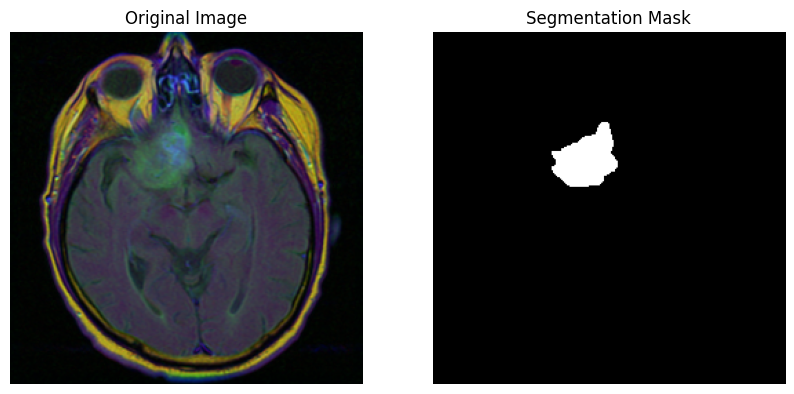

In [32]:
def show_image_and_mask(img_path, mask_path):
    img = np.array(Image.open(img_path).convert("RGB"))
    mask = np.array(Image.open(mask_path).convert("L"))
    fig, axs = plt.subplots(1, 2, figsize=(10, 5))
    axs[0].imshow(img);               axs[0].set_title("Original Image");    axs[0].axis('off')
    axs[1].imshow(mask, cmap='gray'); axs[1].set_title("Segmentation Mask"); axs[1].axis('off')
    plt.show()

for img_path, mask_path in pairs:          # show the first slice that contains a tumour
    if np.array(Image.open(mask_path)).max() > 0:
        show_image_and_mask(img_path, mask_path)
        break

In [33]:
IMG_SIZE = (128, 128)

def load_image_mask_pair(img_path, mask_path, img_size=IMG_SIZE):
    img = Image.open(img_path).convert("RGB").resize(img_size)
    mask = Image.open(mask_path).convert("L").resize(img_size, Image.NEAREST)
    img = np.array(img, dtype=np.float32) / 255.0
    mask = (np.array(mask) > 127).astype(np.float32)[..., np.newaxis]
    return img, mask

def load_split(split_patients, desc):
    split_patients = set(split_patients)
    X, Y = [], []
    for img_path, mask_path in tqdm(pairs, desc=desc):
        if os.path.basename(os.path.dirname(img_path)) in split_patients:
            img, mask = load_image_mask_pair(img_path, mask_path)
            X.append(img); Y.append(mask)
    return np.array(X), np.array(Y)

train_p, temp_p = train_test_split(patients, test_size=0.3, random_state=SEED)
val_p, test_p = train_test_split(temp_p, test_size=0.5, random_state=SEED)

X_train, Y_train = load_split(train_p, "Loading train")
X_val, Y_val = load_split(val_p, "Loading val")
X_test, Y_test = load_split(test_p, "Loading test")

print("Patients train/val/test:", len(train_p), len(val_p), len(test_p))
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)
print(f"Slices with tumour in train set: {(Y_train.max(axis=(1,2,3)) > 0).mean():.1%}")

Loading test: 100%|██████████| 3929/3929 [00:02<00:00, 1809.40it/s]

Patients train/val/test: 77 16 17
Train: (2750, 128, 128, 3) Val: (618, 128, 128, 3) Test: (561, 128, 128, 3)
Slices with tumour in train set: 33.3%


### Loss and metrics (shared by both models)

* `dice_coef` uses `smooth=1`, which keeps gradients useful when predictions are near zero.
* `bce_dice_loss` adds binary cross-entropy to the Dice loss. This combination stops the model from collapsing to "predict background everywhere", which is what happened with a pure Dice loss.

In [34]:
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(K.binary_crossentropy(y_true, y_pred))
    return bce + (1. - dice_coef(y_true, y_pred))

def hard_dice_scores(y_true, y_pred_bin):
    """Per-image Dice on thresholded masks.
    Returns (all_slices, tumour_slices_only).
    all_slices counts an empty prediction on an empty mask as 1, so it is inflated when most slices are empty.
    tumour_slices_only averages only over slices whose ground-truth mask is non-empty (the more honest number)."""
    scores, has_tumour = [], []
    for t, p in zip(y_true, y_pred_bin):
        t, p = t.astype(bool), p.astype(bool)
        denom = t.sum() + p.sum()
        scores.append(1.0 if denom == 0 else 2. * np.logical_and(t, p).sum() / denom)
        has_tumour.append(t.any())
    scores, has_tumour = np.array(scores), np.array(has_tumour)
    return float(scores.mean()), float(scores[has_tumour].mean())

EPOCHS = 15
BATCH_SIZE = 8

# Part 2: Feed-Forward CNN (baseline)

A simple encoder-decoder with no skip connections.

In [35]:
def cb(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation('relu')(x)

def build_ffn_model(input_shape):
    inputs = layers.Input(shape=input_shape)

    x = cb(inputs, 32)
    x = layers.MaxPooling2D()(x)

    x = cb(x, 64)
    x = layers.MaxPooling2D()(x)

    x = cb(x, 128)
    x = layers.UpSampling2D()(x)

    x = cb(x, 64)
    x = layers.UpSampling2D()(x)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(x)
    return models.Model(inputs, outputs, name="feedforward_cnn")

ffn_model = build_ffn_model((*IMG_SIZE, 3))
ffn_model.summary()

Model: "feedforward_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 64, 64, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 128, 128, 1)    │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,257 (657.25 KB)

 Trainable params: 167,681 (655.00 KB)

 Non-trainable params: 576 (2.25 KB)

In [36]:
ffn_model.compile(optimizer=Adam(1e-4), loss=bce_dice_loss, metrics=[dice_coef])

ffn_history = ffn_model.fit(
    X_train, Y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, Y_val)
)

Epoch 1/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - dice_coef: 0.0293 - loss: 1.7391 - val_dice_coef: 0.0324 - val_loss: 1.4420
Epoch 2/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - dice_coef: 0.0465 - loss: 1.2669 - val_dice_coef: 0.0610 - val_loss: 1.1937
Epoch 3/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - dice_coef: 0.0741 - loss: 1.1023 - val_dice_coef: 0.0903 - val_loss: 1.0563
Epoch 4/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - dice_coef: 0.1141 - loss: 0.9955 - val_dice_coef: 0.1198 - val_loss: 0.9744
Epoch 5/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - dice_coef: 0.1716 - loss: 0.8988 - val_dice_coef: 0.1547 - val_loss: 0.9061
Epoch 6/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - dice_coef: 0.2503 - loss: 0.7962 - val_dice_coef: 0.1881 - val_loss: 0.8535
Epoch 7/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - dice_coef: 0.3406 - loss: 0.6928 - val_dice_coef: 0.2103 - val_loss: 0.8248
Epoch 8/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - dice_coef: 0.4184 - loss: 0

# Part 3: U-Net

Compared with the earlier version, this U-Net:
* uses **BatchNormalization** and He initialisation in each conv block,
* uses **BCE + Dice loss** instead of pure Dice,
* uses a lower learning rate (1e-4).

These changes fix the collapse to all-zero predictions seen before.

In [37]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation('relu')(x)

def build_unet_model(input_shape):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 64)
    p1 = layers.MaxPooling2D(2)(c1)
    c2 = conv_block(p1, 128)
    p2 = layers.MaxPooling2D(2)(c2)

    # Bottleneck
    b1 = conv_block(p2, 256)

    # Decoder with skip connections
    u2 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(b1)
    c3 = conv_block(layers.concatenate([u2, c2]), 128)

    u1 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(c3)
    c4 = conv_block(layers.concatenate([u1, c1]), 64)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(c4)
    return models.Model(inputs, outputs, name="unet")

unet_model = build_unet_model((*IMG_SIZE, 3))
unet_model.summary()

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │      1,792 │ input_layer_3[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_21[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_14       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │     36,928 │ activation_14[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_22[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_15       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 64, 64,    │          0 │ activation_15[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_6[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_23[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_16       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 64, 64,    │    147,584 │ activation_16[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_24[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 32, 32,    │          0 │ activation_17[0]… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_7[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_25[0][0] 

 Total params: 1,867,969 (7.13 MB)

 Trainable params: 1,865,409 (7.12 MB)

 Non-trainable params: 2,560 (10.00 KB)

In [38]:
unet_model.compile(optimizer=Adam(1e-4), loss=bce_dice_loss, metrics=[dice_coef])

unet_history = unet_model.fit(
    X_train, Y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, Y_val)
)

Epoch 1/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 57s 130ms/step - dice_coef: 0.1240 - loss: 1.0176 - val_dice_coef: 0.1149 - val_loss: 0.9687
Epoch 2/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 35s 103ms/step - dice_coef: 0.2751 - loss: 0.7756 - val_dice_coef: 0.1903 - val_loss: 0.8602
Epoch 3/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 36s 104ms/step - dice_coef: 0.4298 - loss: 0.6015 - val_dice_coef: 0.2450 - val_loss: 0.7867
Epoch 4/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 36s 103ms/step - dice_coef: 0.5564 - loss: 0.4662 - val_dice_coef: 0.2815 - val_loss: 0.7495
Epoch 5/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 36s 103ms/step - dice_coef: 0.6389 - loss: 0.3801 - val_dice_coef: 0.2904 - val_loss: 0.7437
Epoch 6/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 36s 104ms/step - dice_coef: 0.6884 - loss: 0.3287 - val_dice_coef: 0.2888 - val_loss: 0.7472
Epoch 7/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 36s 103ms/step - dice_coef: 0.7162 - loss: 0.3004 - val_dice_coef: 0.3091 - val_loss: 0.7284
Epoch 8/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 36s 103ms/step - dice_coef: 0

# Part 4: Comparison

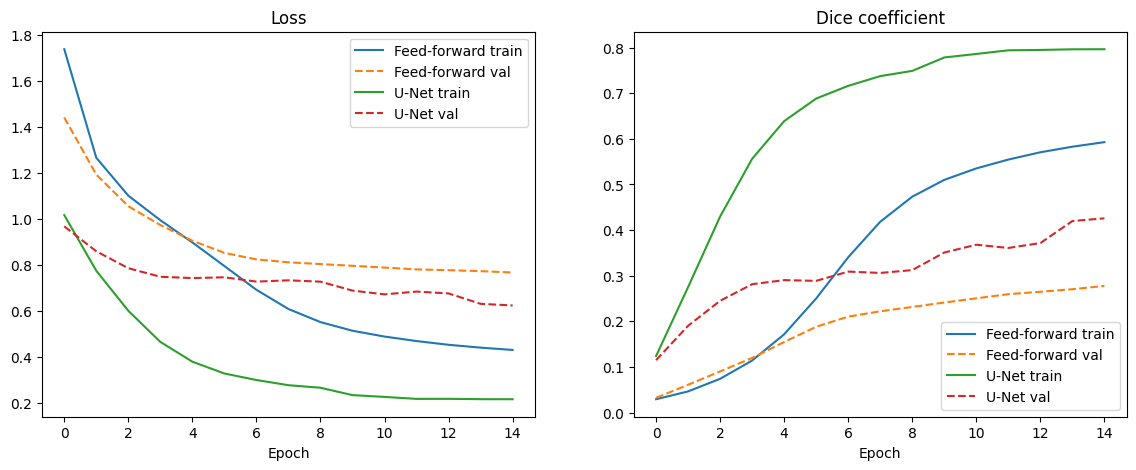

In [39]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for name, h in [("Feed-forward", ffn_history), ("U-Net", unet_history)]:
    axs[0].plot(h.history['loss'], label=f'{name} train')
    axs[0].plot(h.history['val_loss'], '--', label=f'{name} val')
    axs[1].plot(h.history['dice_coef'], label=f'{name} train')
    axs[1].plot(h.history['val_dice_coef'], '--', label=f'{name} val')
axs[0].set_title("Loss"); axs[0].set_xlabel("Epoch"); axs[0].legend()
axs[1].set_title("Dice coefficient"); axs[1].set_xlabel("Epoch"); axs[1].legend()
plt.show()

In [40]:
results = {}
for name, m in [("Feed-forward CNN", ffn_model), ("U-Net", unet_model)]:
    test_loss, test_dice = m.evaluate(X_test, Y_test, verbose=0)
    preds_bin = (m.predict(X_test, verbose=0) > 0.5).astype(np.uint8)
    hard_all, hard_tumour = hard_dice_scores(Y_test, preds_bin)
    results[name] = {"test_loss": test_loss, "soft_dice": test_dice,
                     "hard_all": hard_all, "hard_tumour": hard_tumour,
                     "pred_pixels": int(preds_bin.sum())}

print(f"{'Model':<18}{'Test loss':>11}{'Soft Dice':>11}{'Hard (all)':>12}{'Hard (tumour)':>15}{'Pred px':>10}")
for name, r in results.items():
    print(f"{name:<18}{r['test_loss']:>11.4f}{r['soft_dice']:>11.4f}{r['hard_all']:>12.4f}{r['hard_tumour']:>15.4f}{r['pred_pixels']:>10d}")
print("\nIf 'Pred px' is 0 the model predicts only background. 'Hard (all)' is inflated by empty slices; compare models on 'Hard (tumour)'.")

Model               Test loss  Soft Dice  Hard (all)  Hard (tumour)   Pred px
Feed-forward CNN       0.6793     0.4110      0.6370         0.3989    111508
U-Net                  0.4548     0.6238      0.7740         0.5635    109320

If 'Pred px' is 0 the model predicts only background. 'Hard (all)' is inflated by empty slices; compare models on 'Hard (tumour)'.


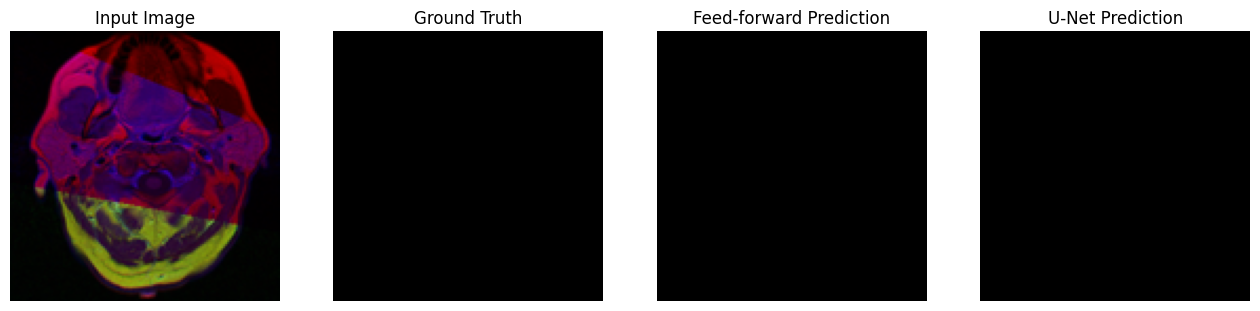

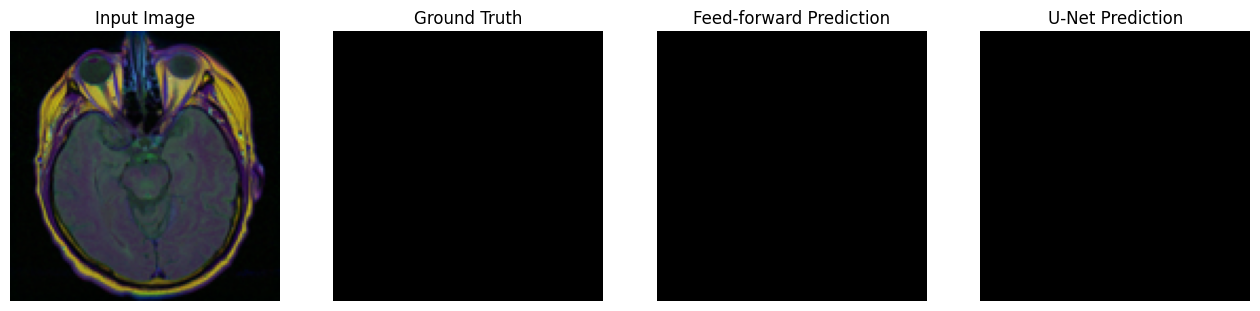

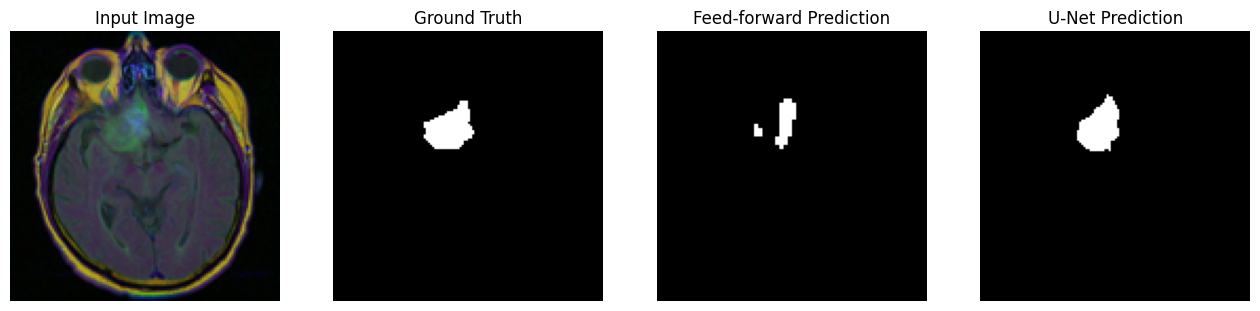

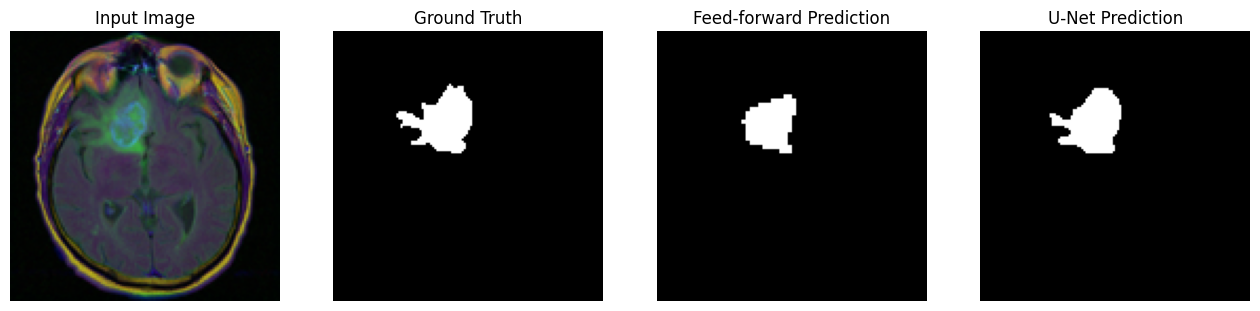

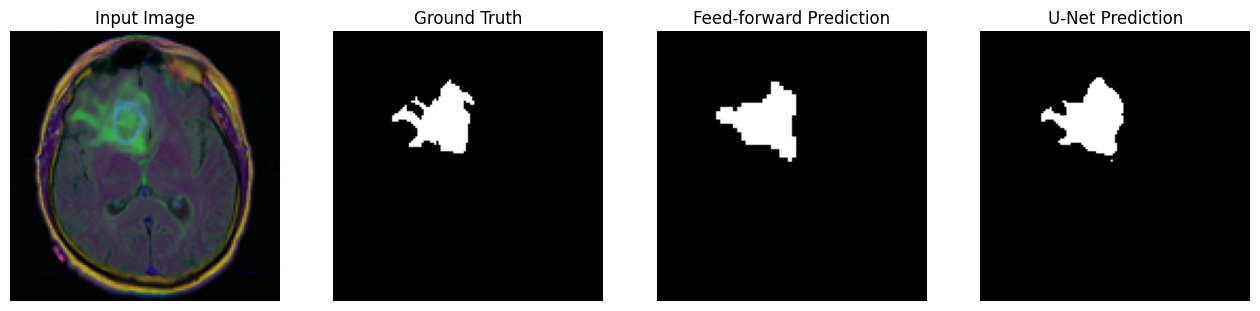

In [41]:
N = 5
ffn_preds = (ffn_model.predict(X_test[:N], verbose=0) > 0.5).astype(np.uint8)
unet_preds = (unet_model.predict(X_test[:N], verbose=0) > 0.5).astype(np.uint8)

for i in range(N):
    fig, axs = plt.subplots(1, 4, figsize=(16, 4))
    panels = [(X_test[i], "Input Image", None),
              (Y_test[i].squeeze(), "Ground Truth", 'gray'),
              (ffn_preds[i].squeeze(), "Feed-forward Prediction", 'gray'),
              (unet_preds[i].squeeze(), "U-Net Prediction", 'gray')]
    for ax, (im, title, cmap) in zip(axs, panels):
        ax.imshow(im, cmap=cmap); ax.set_title(title); ax.axis('off')
    plt.show()